# ChurnGuard AI · 01 — Análise Exploratória de Dados

**Pergunta de negócio:** *quais clientes apresentam maior risco de cancelar e quais fatores contribuem para esse risco?*

Este notebook explora a base analítica (cliente × mês) antes da modelagem. Toda a lógica está em
`ml/src/eda/analysis.py`; aqui fica a narrativa. O relatório completo e versionado está em `docs/eda.md`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parents[1] if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import display

from ml.src import config
from ml.src.data.build_analytical_base import load_raw
from ml.src.eda import analysis as A
from ml.src.viz import style as S

S.apply()
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
%matplotlib inline

## 1. Tabelas brutas e qualidade

In [2]:
raw_files = ["customers", "plans", "usage_monthly", "payments", "tickets", "surveys", "price_adjustments"]
raw_full = {n: pd.read_csv(config.RAW_DIR / f"{n}.csv") for n in raw_files}
A.raw_quality_summary(raw_full)

,tabela,registros,colunas,duplicatas_exatas,células_ausentes_%
0,customers,9025,14,25,6.91
1,plans,4,5,0,0.00
2,usage_monthly,117184,8,0,0.36
3,payments,109732,7,0,0.03
4,tickets,47410,7,0,6.42
5,surveys,13271,3,0,0.00
6,price_adjustments,4,3,0,0.00


In [3]:
raw = load_raw()  # já remove as 25 duplicatas exatas do cadastro
raw["customers"].head()

,customer_id,nome,idade,regiao,tipo_cliente,plano_id,ciclo_contrato,forma_pagamento,renovacao_automatica,canal_aquisicao,data_inicio,data_cancelamento,motivo_cancelamento,status
0,CLI-00001,Prisma Comércio EIRELI,50.00,Sudeste,Pequena Empresa,2,Mensal,Boleto,True,Indicação,2026-01-23,NaT,NaN,Ativo
1,CLI-00002,Karina Duarte,37.00,Sul,Pessoa Física,1,Anual,Pix,False,Anúncios pagos,2024-11-27,2025-08-14,Insatisfação com atendimento,Cancelado
2,CLI-00003,Ponte Imóveis ME,32.00,Nordeste,Pequena Empresa,1,Mensal,Boleto,False,Orgânico,2026-04-05,2026-08-17,Baixa utilização,Cancelado
3,CLI-00004,Juliana Vasconcelos,67.00,Nordeste,Pessoa Física,2,Anual,Boleto,True,Orgânico,2025-11-08,NaT,NaN,Ativo
4,CLI-00005,Camila Nogueira,30.00,Sudeste,Pessoa Física,1,Mensal,Cartão de crédito,True,Orgânico,2022-11-02,2023-10-08,Baixa utilização,Cancelado


## 2. Base analítica

Uma linha por **cliente ativo × data de referência** (fim de mês). O rótulo `churn` indica cancelamento nos
**60 dias seguintes**. Todas as agregações respeitam o que era conhecido na data de referência (*point-in-time*).

In [4]:
base = pd.read_parquet(config.ANALYTICAL_BASE_FILE)
print(f"{len(base):,} registros × {base.shape[1]} variáveis | {base.customer_id.nunique():,} clientes | churn = {base.churn.mean():.2%}")
A.data_profile(base.drop(columns=["nome"]))

71,176 registros × 42 variáveis | 6,856 clientes | churn = 8.37%


,tipo,ausentes,ausentes_%,valores_unicos,exemplo
customer_id,str,0,0.00,6856,CLI-00026
data_referencia,datetime64[us],0,0.00,26,2024-06-30 00:00:00
idade,float64,2267,3.19,65,43.00
regiao,str,337,0.47,5,Sudeste
tipo_cliente,str,0,0.00,3,Pessoa Física
plano,str,0,0.00,4,Essencial
funcionalidades_disponiveis,int64,0,0.00,4,9
ciclo_contrato,str,0,0.00,2,Mensal
forma_pagamento,str,0,0.00,4,Boleto
renovacao_automatica,int64,0,0.00,2,0


In [5]:
base.drop(columns=["nome"]).describe().T

,count,mean,min,25%,50%,75%,max,std
data_referencia,71176,2025-09-04 19:26:48.811958,2024-06-30 00:00:00,2025-02-28 00:00:00,2025-09-30 00:00:00,2026-03-31 00:00:00,2026-07-31 00:00:00,NaN
idade,"68,909.00",39.37,0.00,31.00,39.00,47.00,150.00,11.49
funcionalidades_disponiveis,"71,176.00",10.06,5.00,5.00,9.00,14.00,20.00,4.47
renovacao_automatica,"71,176.00",0.71,0.00,0.00,1.00,1.00,1.00,0.46
tempo_cliente_meses,"71,176.00",13.18,1.00,4.70,9.90,19.00,54.80,10.69
acessos_m1,"71,176.00",70.60,0.00,30.00,50.00,85.00,"1,096.00",69.18
acessos_m2,"71,071.00",68.91,0.00,29.00,49.00,84.00,"1,096.00",68.94
acessos_m3,"65,865.00",69.63,0.00,30.00,49.00,84.00,"1,096.00",69.46
acessos_m4,"61,016.00",70.21,0.00,30.00,50.00,85.00,"1,096.00",69.79
acessos_m5,"56,533.00",70.66,0.00,30.00,50.00,86.00,"1,096.00",69.90


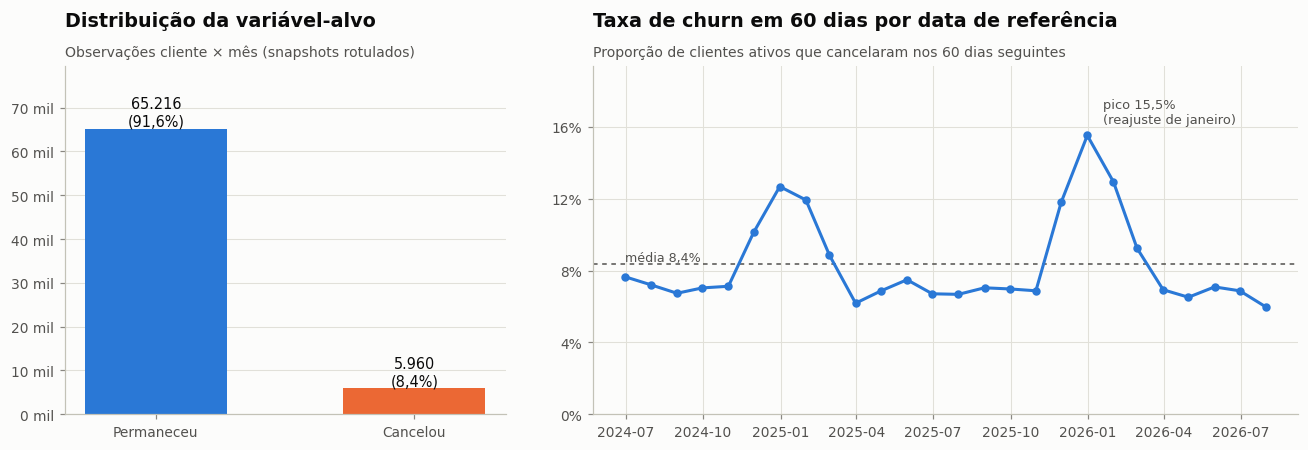

In [6]:
d = A.add_eda_helpers(base)
fig = A.plot_target_distribution(d)

> **Desbalanceamento:** um modelo que sempre responde "não cancela" acerta ~92% — e não encontra nenhum cliente em risco.
> Por isso a acurácia não será a métrica principal.

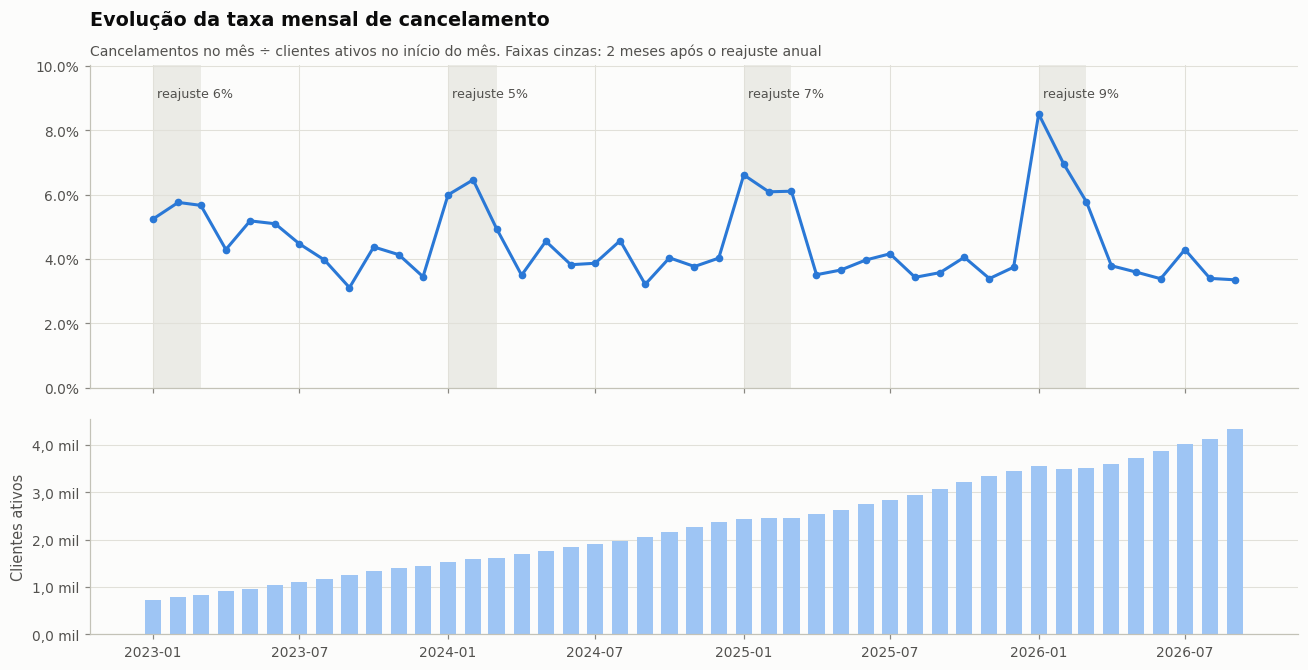

In [7]:
fig, monthly = A.plot_monthly_churn(raw["customers"], raw_full["price_adjustments"])

## 3. Churn por dimensão de negócio

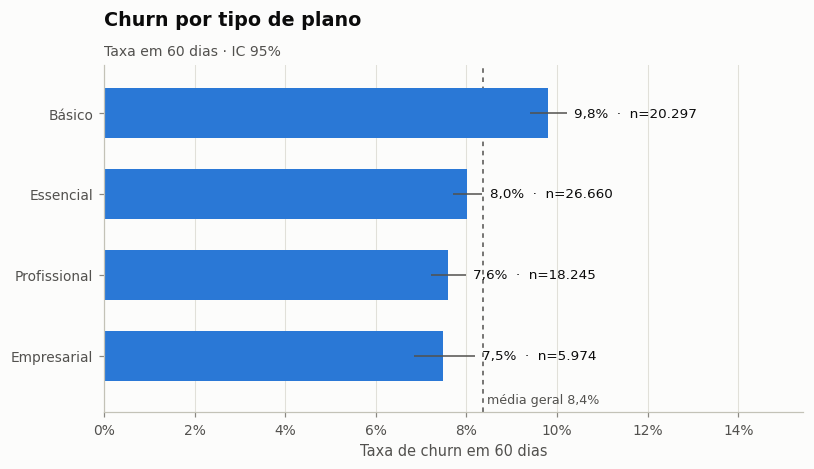

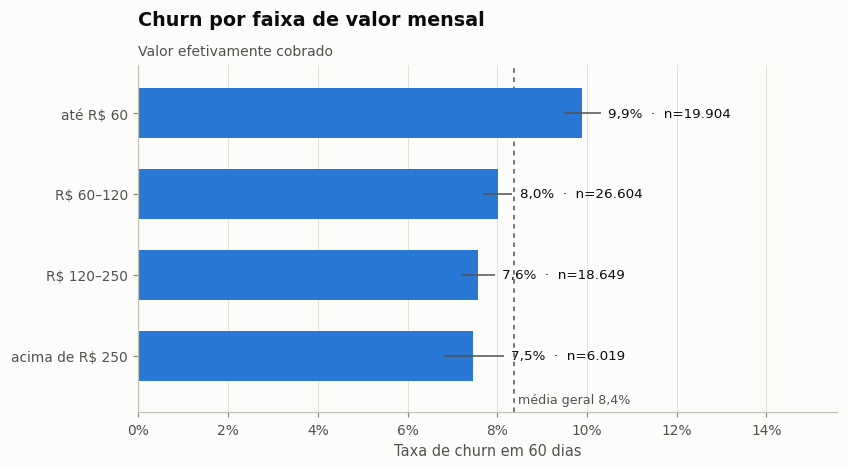

In [8]:
A.plot_rate_bars(d, "plano", "Churn por tipo de plano", "Taxa em 60 dias · IC 95%",
                 order=["Básico", "Essencial", "Profissional", "Empresarial"])
A.plot_rate_bars(d, "faixa_preco", "Churn por faixa de valor mensal", "Valor efetivamente cobrado",
                 order=["até R$ 60", "R$ 60–120", "R$ 120–250", "acima de R$ 250"]);

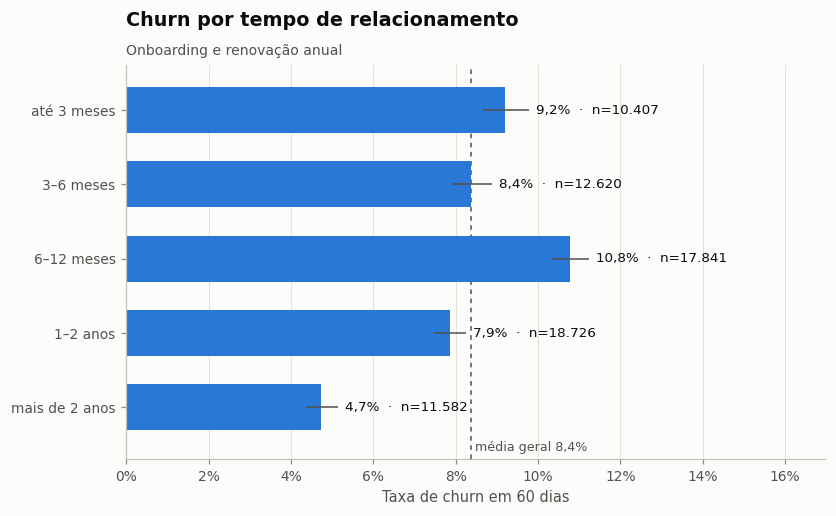

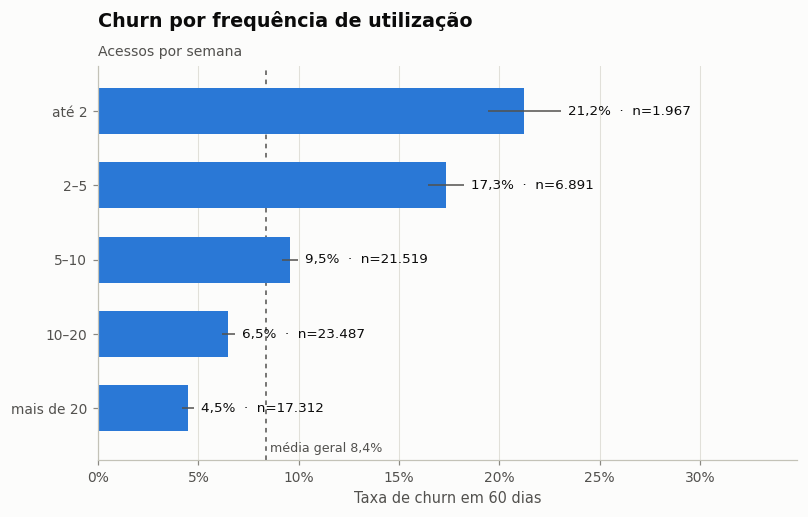

In [9]:
A.plot_rate_bars(d, "faixa_tempo", "Churn por tempo de relacionamento", "Onboarding e renovação anual",
                 order=["até 3 meses", "3–6 meses", "6–12 meses", "1–2 anos", "mais de 2 anos"])
A.plot_rate_bars(d, "faixa_uso", "Churn por frequência de utilização", "Acessos por semana",
                 order=["até 2", "2–5", "5–10", "10–20", "mais de 20"]);

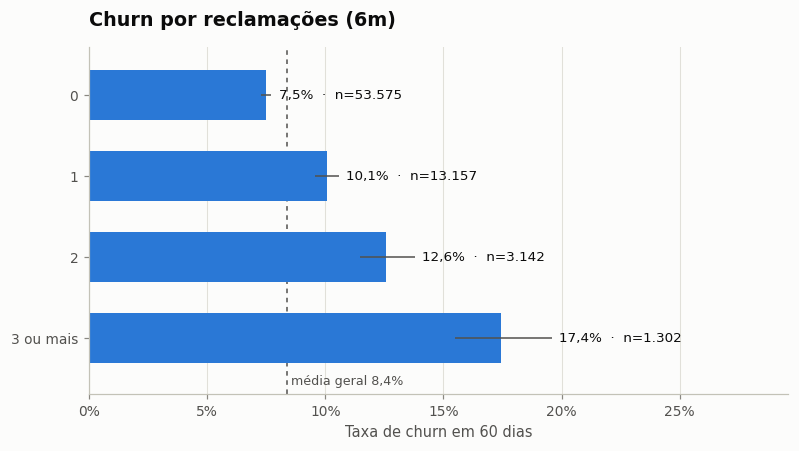

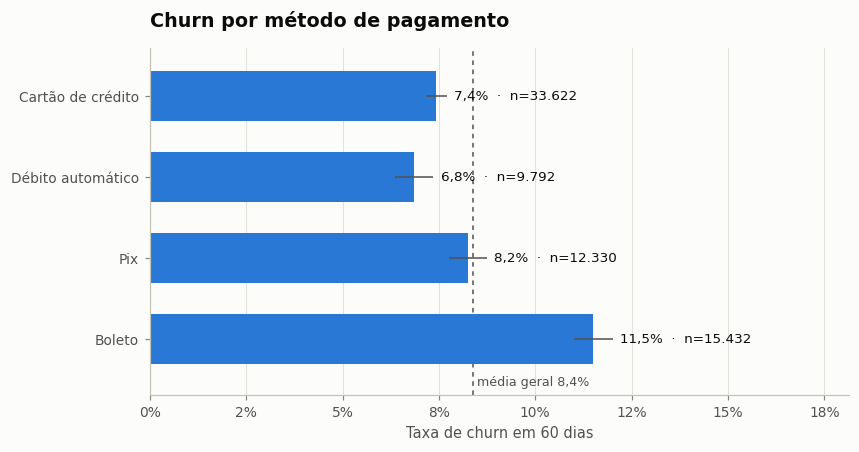

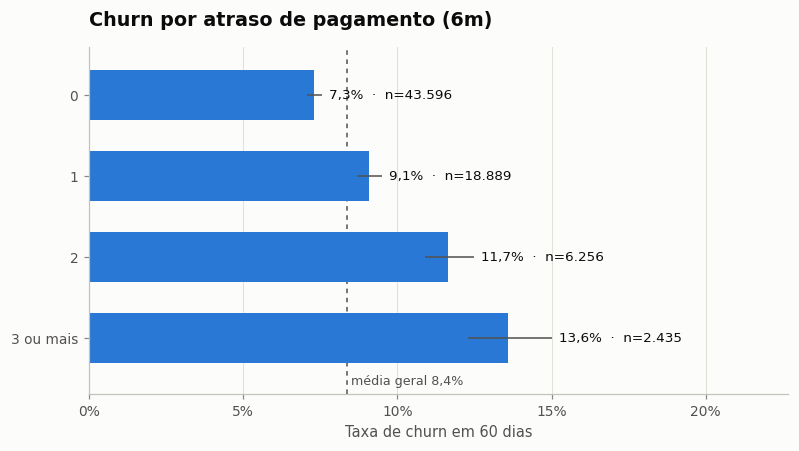

In [10]:
A.plot_rate_bars(d, "faixa_reclamacoes", "Churn por reclamações (6m)", "",
                 order=["0", "1", "2", "3 ou mais"])
A.plot_rate_bars(d, "forma_pagamento", "Churn por método de pagamento", "",
                 order=["Cartão de crédito", "Débito automático", "Pix", "Boleto"])
A.plot_rate_bars(d, "faixa_atrasos", "Churn por atraso de pagamento (6m)", "",
                 order=["0", "1", "2", "3 ou mais"]);

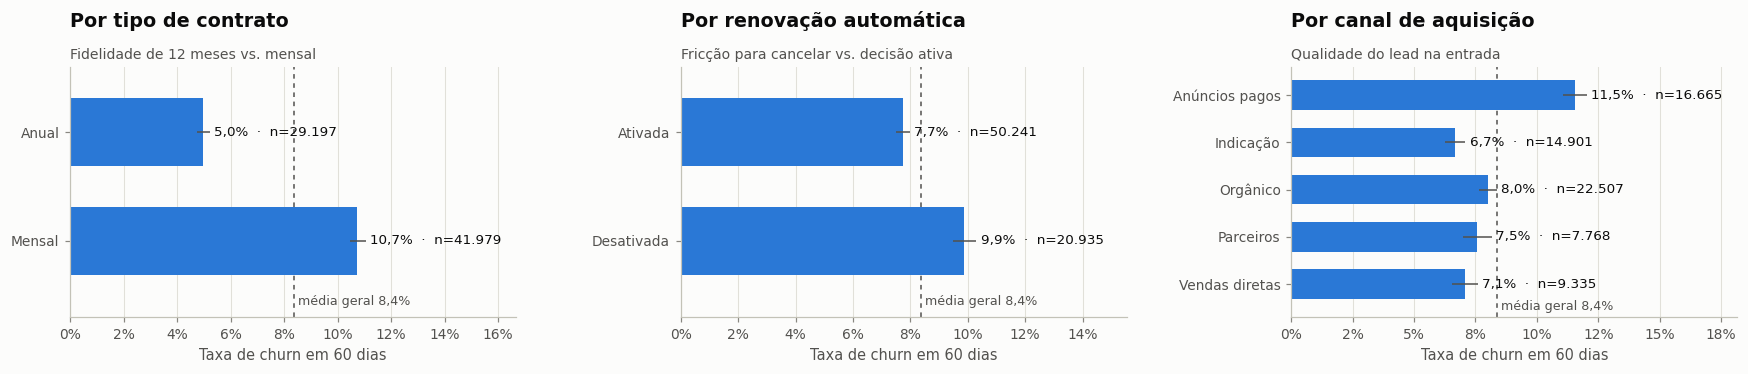

In [11]:
fig = A.plot_contract_panel(d)

## 4. Mudança de comportamento

O gráfico mais importante da EDA: **quem cancela reduz o uso nos meses anteriores**. Isso guia a engenharia de atributos.

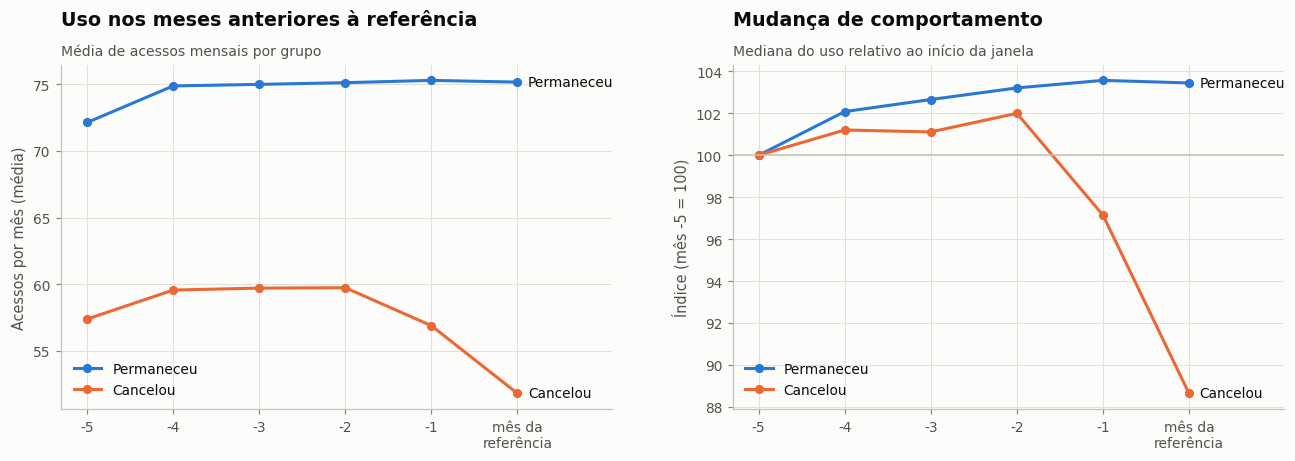

In [12]:
fig = A.plot_usage_trajectory(d)

## 5. Comparação entre grupos e distribuições

In [13]:
A.class_comparison(d, ["acessos_semana", "variacao_uso_3m", "dias_desde_ultimo_acesso", "funcionalidades_usadas_m1",
                        "faturas_atrasadas_6m", "tickets_3m", "reclamacoes_6m", "ultima_nota_satisfacao",
                        "tempo_cliente_meses", "valor_mensal"])

,média_permaneceu,média_cancelou,mediana_permaneceu,mediana_cancelou,diferença_%
dias_desde_ultimo_acesso,3.47,7.09,1.00,2.00,104.40
reclamacoes_6m,0.32,0.48,0.00,0.00,50.40
faturas_atrasadas_6m,0.54,0.72,0.00,0.00,33.60
acessos_semana,16.76,11.30,12.01,7.85,-32.60
funcionalidades_usadas_m1,5.68,4.26,5.00,4.00,-24.90
tickets_3m,1.09,1.32,1.00,1.00,21.30
variacao_uso_3m,0.29,0.24,0.05,-0.02,-18.70
tempo_cliente_meses,13.34,11.40,10.10,9.40,-14.50
ultima_nota_satisfacao,7.64,7.18,8.00,7.00,-6.00
valor_mensal,140.96,134.83,99.90,99.90,-4.40


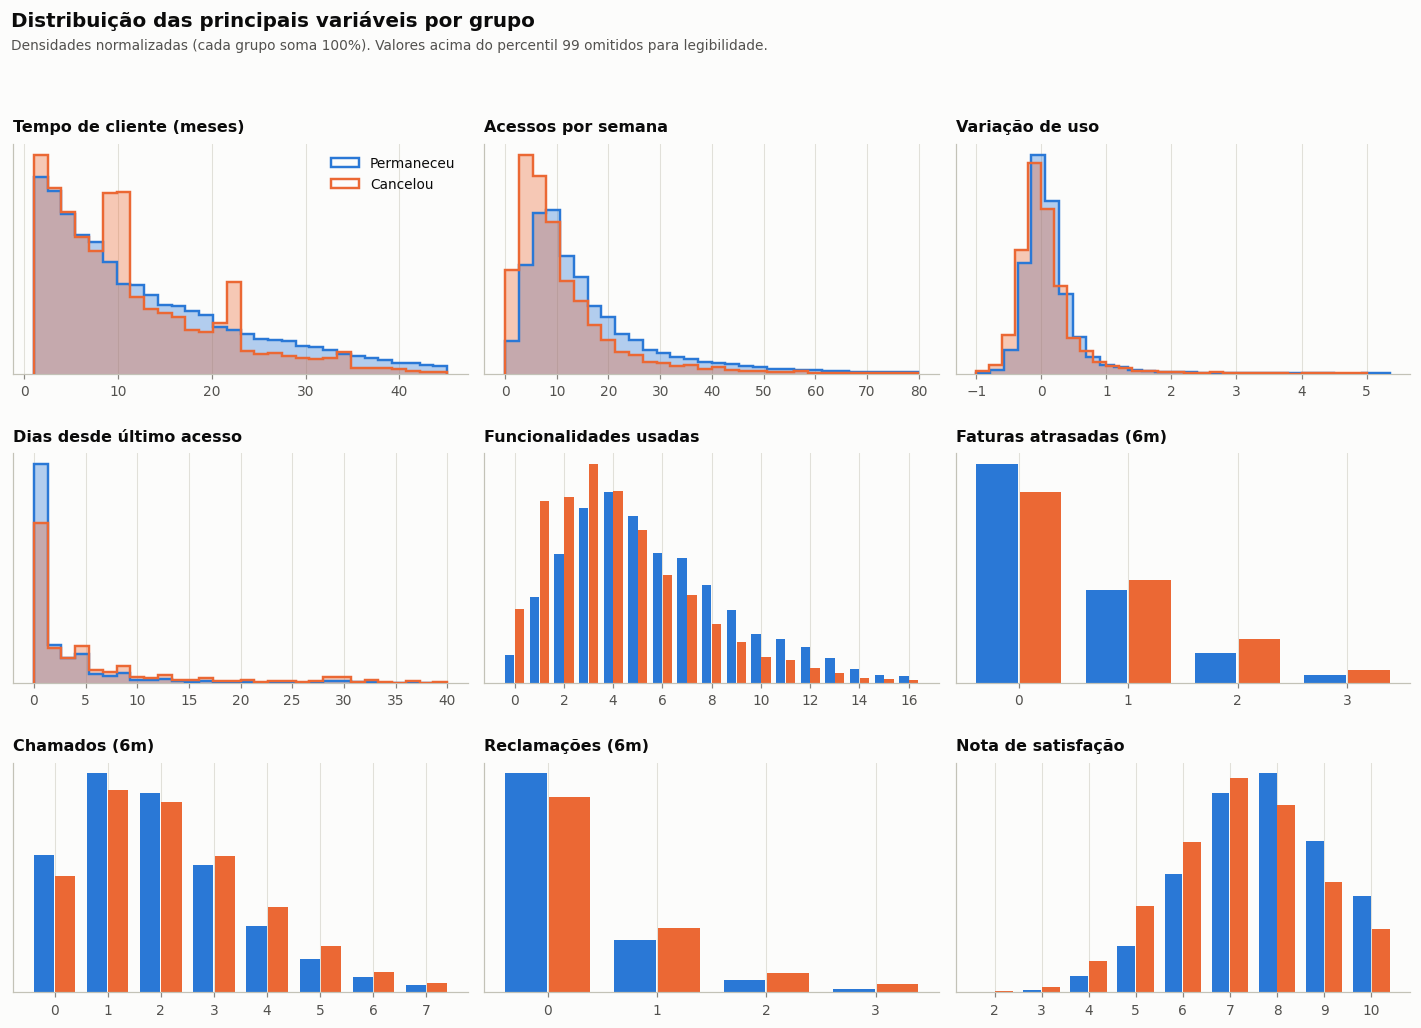

In [14]:
fig = A.plot_numeric_distributions(d, {
    "tempo_cliente_meses": "Tempo de cliente (meses)", "acessos_semana": "Acessos por semana",
    "variacao_uso_3m": "Variação de uso", "dias_desde_ultimo_acesso": "Dias desde último acesso",
    "funcionalidades_usadas_m1": "Funcionalidades usadas", "faturas_atrasadas_6m": "Faturas atrasadas (6m)",
    "tickets_6m": "Chamados (6m)", "reclamacoes_6m": "Reclamações (6m)", "ultima_nota_satisfacao": "Nota de satisfação"})

## 6. Correlação, outliers e ausentes

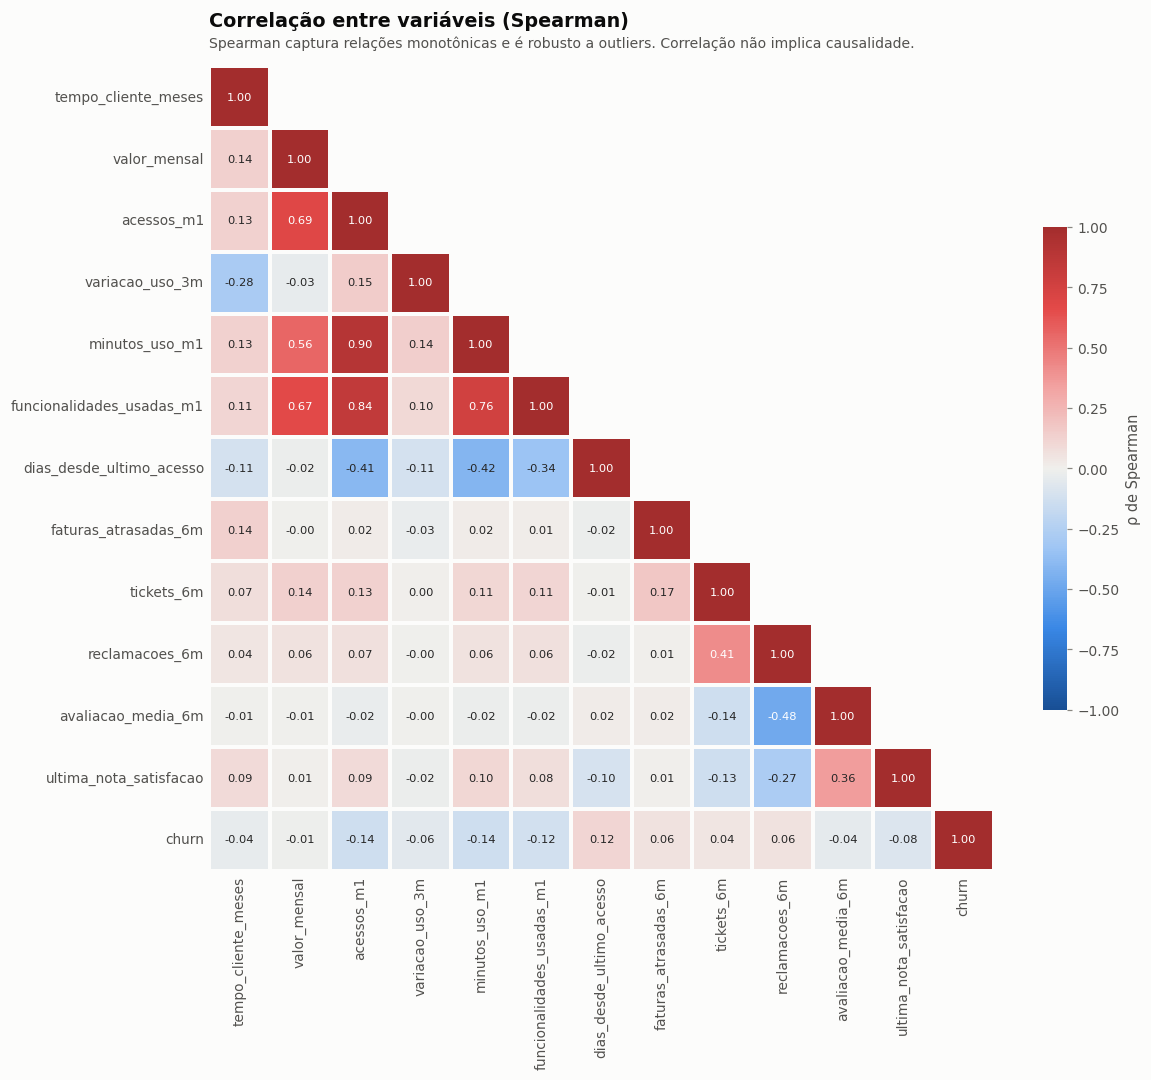

In [15]:
cols = ["tempo_cliente_meses", "valor_mensal", "acessos_m1", "variacao_uso_3m", "minutos_uso_m1",
        "funcionalidades_usadas_m1", "dias_desde_ultimo_acesso", "faturas_atrasadas_6m", "tickets_6m",
        "reclamacoes_6m", "avaliacao_media_6m", "ultima_nota_satisfacao", "churn"]
fig, corr = A.plot_correlation(d, cols)

,variável,Q1,Q3,limite_inferior,limite_superior,outliers,outliers_%,máximo
0,minutos_uso_m1,510.00,"1,797.25","-1,420.88","3,728.12",5801,8.15,"230,359.00"
1,acessos_m1,30.00,85.00,-52.50,167.50,5373,7.55,"1,096.00"
2,tempo_medio_resolucao_h_6m,7.90,23.92,-16.14,47.96,3530,5.96,677.90
3,valor_mensal,54.39,181.81,-136.74,372.94,5974,8.39,648.92


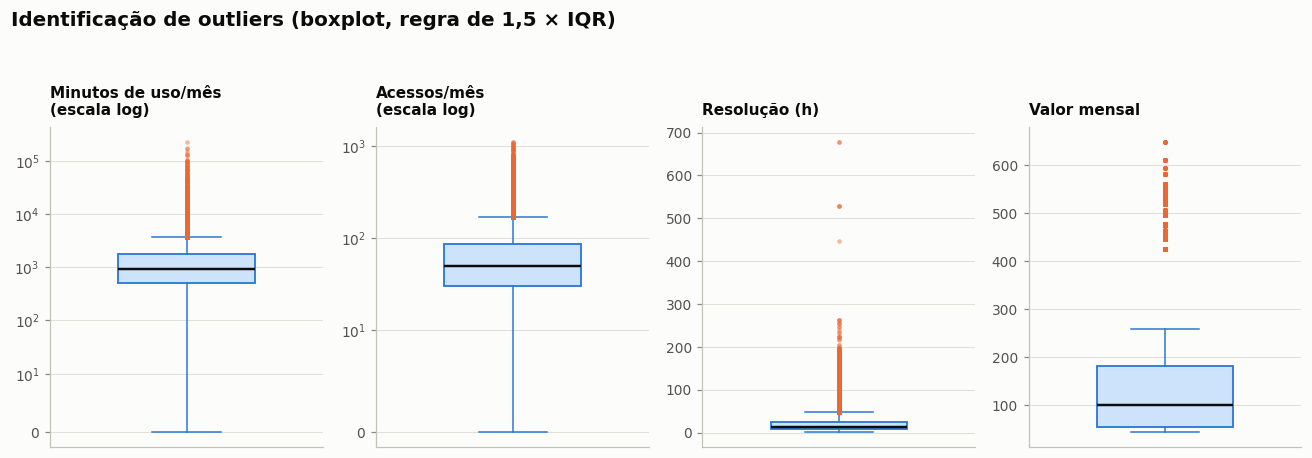

In [16]:
out_cols = {"minutos_uso_m1": "Minutos de uso/mês", "acessos_m1": "Acessos/mês",
            "tempo_medio_resolucao_h_6m": "Resolução (h)", "valor_mensal": "Valor mensal"}
display(A.outlier_summary(d, list(out_cols)))
fig = A.plot_outliers(d, out_cols, log_cols=("minutos_uso_m1", "acessos_m1"))

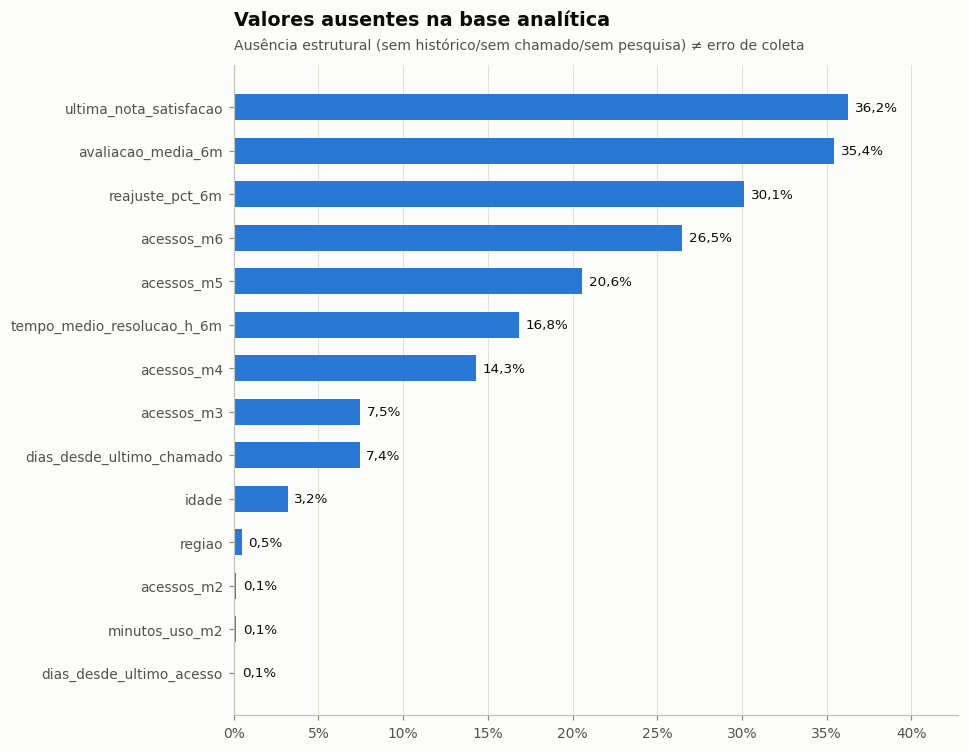

In [17]:
fig = A.plot_missing(base.drop(columns=["nome"]))

## 7. Checagem de atributos sensíveis

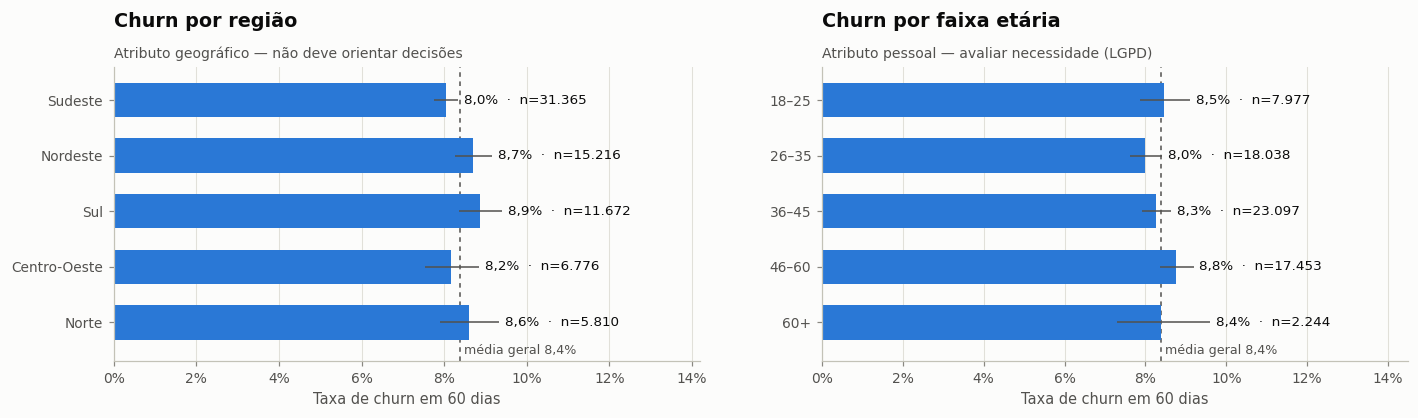

In [18]:
fig = A.plot_fairness_check(d)

Região e idade **não mostram diferença relevante** de churn (intervalos sobrepostos). Como não trazem sinal e têm
potencial discriminatório, ficam **fora do modelo** e são usadas apenas para auditoria de viés.

## 8. Conclusões para a modelagem

1. Base desbalanceada (~11:1) → PR-AUC, Recall, Precision; balanceamento avaliado só no treino.
2. Dinâmica temporal (picos pós-reajuste) → divisão treino/teste por data, com intervalo de 60 dias.
3. Queda de uso é o sinal mais forte → atributos de tendência e recência.
4. Uso depende do plano → normalizar pela capacidade do plano.
5. Atrito financeiro e de suporte somam risco → taxas de atraso, reclamações por mês.
6. Ausência carrega informação → *flags* de ausência.
7. Colunas pós-evento (`data_cancelamento`, `motivo_cancelamento`, `status`) nunca entram como atributo.